# 05 · Near-failure classification

**Why:** exact-RIR video predictions were weak and often nearly constant.

**Question:** is the narrower decision easier: **RIR 0–2 versus more than 2**? This separate classification experiment does not replace exact RIR or establish a physiological measure of fatigue.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "training/notebooks").is_dir()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from training.reporting import (
    RUNS,
    LABELS,
    result_folder,
    load_predictions,
    assert_matched_examples,
    regression_report,
    classification_report,
    metrics_table,
    plot_errors,
    plot_participants,
    plot_diagnostics,
    plot_warnings,
)

OUTPUT = ROOT / "training/artifacts/submission_report"
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 44)


## Experiment 6 · Binary warning

**Change:** compare constant rules, the old RIR≤2 rule, rep-duration/video-feature logistic models, and a separately trained R3D classifier.  
**Test:** 97 reps from six people, starting at rep 4; participant-separated outer folds; inner selection of regularization/epochs; decision threshold fixed at 0.5.

,condition,model,examples,people,seeds,balanced_accuracy,precision,recall,specificity,f1,average_precision,roc_auc,brier
0,Near failure ≤ 2 RIR,Always farther from failure,97,6,1,0.500,0.000,0.000,1.000,0.000,0.372,0.500,0.372
1,Near failure ≤ 2 RIR,Always near failure,97,6,1,0.500,0.372,1.000,0.000,0.513,0.372,0.500,0.628
2,Near failure ≤ 2 RIR,Rep durations,97,6,1,0.525,0.350,0.583,0.467,0.360,0.688,0.724,0.240
3,Near failure ≤ 2 RIR,Existing RIR ≤ 2 rule,97,6,1,0.500,0.000,0.000,1.000,0.000,0.372,0.500,0.372
4,Near failure ≤ 2 RIR,Adapted R3D classifier,97,6,3,0.502,0.328,0.889,0.116,0.451,0.444,0.519,0.260
5,Near failure ≤ 2 RIR,Video + rep durations,97,6,1,0.560,0.411,0.889,0.231,0.529,0.574,0.673,0.347
6,Near failure ≤ 2 RIR,Video features,97,6,1,0.525,0.395,0.778,0.273,0.471,0.573,0.670,0.350


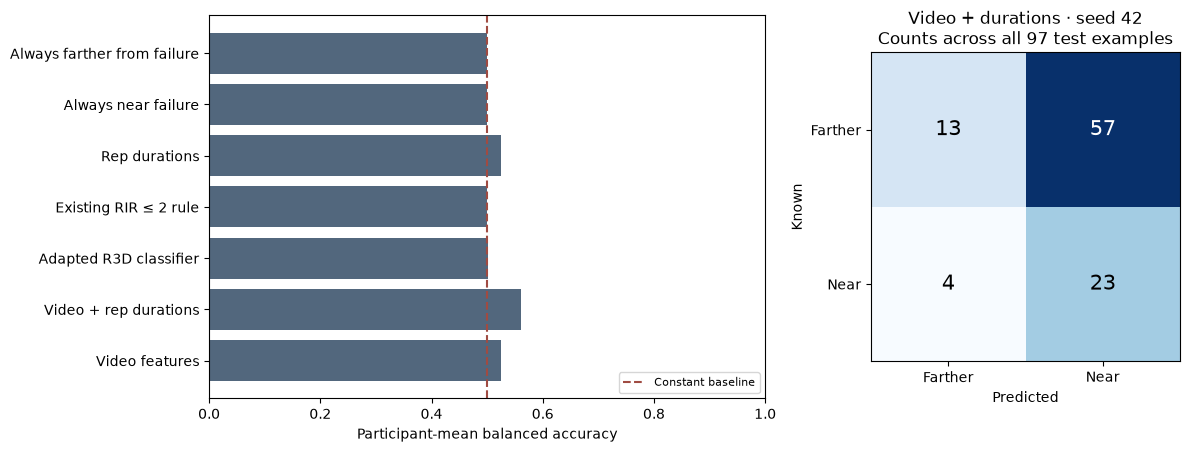

In [2]:
warning_predictions = load_predictions(ROOT, "classification", "Near failure ≤ 2 RIR")
assert_matched_examples(warning_predictions)
warning_scores, warning_people = classification_report(warning_predictions)
display(metrics_table(warning_scores, classification=True))
plot_warnings(
    warning_scores, warning_predictions, path=OUTPUT / "05_warning_comparison.png"
)
plt.show()
warning_scores.to_csv(OUTPUT / "05_warning_metrics.csv", index=False)
warning_people.to_csv(OUTPUT / "05_warning_participants.csv", index=False)


**Result:** video + durations reached about 56% balanced accuracy, with 89% recall but only 23% specificity. It found many near-failure reps but also warned on many farther-from-failure reps. The neural classifier stayed near the 50% constant-reference level.

**Next question:** can explicit small-motion measurements add information beyond speed? See notebook 06.

## Reading the metrics

- **Recall:** how many truly near-failure reps were detected?
- **Precision:** how many warnings were correct?
- **Specificity:** how often did farther-from-failure reps avoid a false warning?
- **Balanced accuracy:** average of recall and specificity; constant near/far rules score 50% here.
- **F1:** combines precision and recall; it does not account for true negatives.
- **Average precision / ROC AUC:** ranking quality across thresholds. Average precision depends on prevalence.
- **Brier / balanced log loss:** probability error; lower is better. Class-balanced training does not guarantee calibrated probabilities.

All table metrics average participants, then seeds. The confusion matrix shows raw counts for one fixed seed. Ordinary accuracy is saved in the CSV, but it can look good simply by predicting the majority class.

## Classification implementation

The classifier predicts whether the reviewed RIR label falls within zero to two remaining reps. Its training and evaluation are separate from the earlier exact-RIR regression experiments.

In [3]:
RUN_NEAR_FAILURE = False

In [4]:
if RUN_NEAR_FAILURE:
    from pathlib import Path
    from datetime import datetime, timezone
    from importlib.metadata import version
    import os
    os.environ["WANDB_DISABLE_CODE"] = "true"
    os.environ["WANDB_DISABLE_GIT"] = "true"
    os.environ["OTEL_SDK_DISABLED"] = "true"
    import copy
    import hashlib
    import json
    import random
    import time
    
    import cv2
    import numpy as np
    import pandas as pd
    import matplotlib
    matplotlib.use("module://matplotlib_inline.backend_inline")
    import matplotlib.pyplot as plt
    import torch
    from torch import nn
    from torch.nn import functional as F
    from torch.utils.data import Dataset, DataLoader
    from torchvision.models import resnet18, ResNet18_Weights
    import wandb
    from IPython.display import display
    
    RUN_MODE = "pilot"
    RESUME_RUN_DIR = None
    WANDB_MODE = "offline"
    WANDB_PROJECT = "replens-video-pilot"
    MODEL_NAMES = ["tcn", "lstm"]
    HIDDEN_SIZE = 64
    BATCH_SIZE = 4
    ENCODER_BATCH_SIZE = 16
    LEARNING_RATE = 0.001
    WEIGHT_DECAY = 0.0001
    PATIENCE = 5
    
    if RUN_MODE not in {"smoke", "pilot"} or WANDB_MODE not in {"offline", "online", "disabled"}:
        raise ValueError("Choose a supported run/tracking mode.")
    if not MODEL_NAMES or not set(MODEL_NAMES).issubset({"tcn", "lstm"}):
        raise ValueError("Choose tcn and/or lstm.")
    MAX_EPOCHS = 2 if RUN_MODE == "smoke" else 25
    SEEDS = [42] if RUN_MODE == "smoke" else [42, 43, 44]
    ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
                 if (path / ".git").is_dir() and (path / "training" / "notebooks").is_dir()), None)
    if ROOT is None:
        raise RuntimeError("Open this notebook from the RepLens project folder.")
    DATA_DIR = ROOT / "training" / "data"
    VIDEO_VARIANT = "cropped"
    VIDEO_DIR = DATA_DIR / ("cropped_videos" if VIDEO_VARIANT == "cropped" else "videos")
    MODEL_DIR = ROOT / "training" / "models"
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    torch.hub.set_dir(str(MODEL_DIR / "torch"))
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    cv2.setNumThreads(1)
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    
    
    def sha256_file(path):
        digest = hashlib.sha256()
        with Path(path).open("rb") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                digest.update(chunk)
        return digest.hexdigest()
    
    
    candidates = sorted((DATA_DIR / "prepared").glob("history_*_reps/*/preparation.json"), key=lambda path: path.stat().st_mtime, reverse=True)
    label_hash = sha256_file(DATA_DIR / "processed" / "reviewed_reps.csv")
    inventory_hash = sha256_file(DATA_DIR / "video_manifest.csv")
    PREPARATION_DIR = None
    for candidate in candidates:
        report = json.loads(candidate.read_text())
        config = report["configuration"]
        if (config["label_sha256"] == label_hash and config["inventory_sha256"] == inventory_hash
                and config.get("candidate_sha256") == sha256_file(DATA_DIR / "processed" / "candidate_reps.csv")
                and config.get("video_variant", "original") == VIDEO_VARIANT
                and (VIDEO_VARIANT != "cropped" or config.get("crop_exports_sha256") == sha256_file(DATA_DIR / "review/whole_lifter_crops/exports.json"))):
            PREPARATION_DIR = candidate.parent
            break
    if PREPARATION_DIR is None:
        raise RuntimeError("No preparation matches the current reviews. Run notebook 02 again.")
    print("Video framing:", VIDEO_VARIANT)
    windows = pd.read_csv(PREPARATION_DIR / "windows.csv")
    inference_windows = pd.read_csv(PREPARATION_DIR / "inference_windows.csv")
    if not inference_windows.empty and inference_windows.reps_left.notna().any():
        raise ValueError("Prediction-only windows must not contain training targets.")
    encoding_windows = pd.concat([windows, inference_windows], ignore_index=True)
    folds = json.loads((PREPARATION_DIR / "folds.json").read_text())
    with np.load(PREPARATION_DIR / "timestamps.npz", allow_pickle=False) as arrays:
        timestamps = {key: arrays[key].copy() for key in arrays.files}
    if RUN_MODE == "smoke":
        folds = folds[:1]
    if windows.empty or not np.isfinite(windows.reps_left).all():
        raise ValueError("Training windows/targets are missing or invalid.")
    DATASET_SCOPE = config.get("dataset_scope", "confirmed")
    accepted_labels = ["collector_confirmed_failure", "reviewer_confirmed_failure"]
    if DATASET_SCOPE == "exploratory":
        accepted_labels.append("user_reported_failure")
        print("EXPLORATORY: some targets use user-reported endpoints; public-source reuse permission is unverified.")
    if not windows.rir_label_status.isin(accepted_labels).all():
        raise ValueError("Resolve unsupported labels before training.")
    for _, group in encoding_windows.groupby("video_id"):
        source = (VIDEO_DIR / group.relative_path.iloc[0]).resolve()
        if not source.is_relative_to(VIDEO_DIR.resolve()) or sha256_file(source) != group.video_sha256.iloc[0]:
            raise ValueError("A source video changed after preparation.")
    for fold in folds:
        outer, test = set(fold["outer_train_participants"]), set(fold["test_participants"])
        if not outer.isdisjoint(test):
            raise ValueError("Participant leakage in outer folds.")
        for inner in fold["inner_validation"]:
            train, validation = set(inner["train_participants"]), set(inner["validation_participants"])
            if not train.isdisjoint(validation) or train | validation != outer:
                raise ValueError("Invalid inner validation split.")
    print(f"Mode: {RUN_MODE} | Device: {DEVICE} | Windows: {len(windows)} | Outer folds: {len(folds)}")
    print("Preparation:", PREPARATION_DIR.name)
    print(f"Prediction-only windows: {len(inference_windows)} across {inference_windows.video_id.nunique()} clips; excluded from training and accuracy.")
    
    print(f"Training dataset: {windows.video_id.nunique()} clips, {windows.participant_id.nunique()} people, {len(windows)} labeled reps.")


In [5]:
if RUN_NEAR_FAILURE:
    def set_seed(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
    
    
    class VideoWindows(Dataset):
        def __init__(self, table):
            self.table = table.reset_index(drop=True)
    
        def __len__(self):
            return len(self.table)
    
        def __getitem__(self, index):
            row = self.table.iloc[index]
            start, stop = int(row.frame_start), int(row.frame_stop_exclusive)
            values = features[row.video_id][start:stop]
            times = timestamps[row.video_id][start:stop]
            if not len(values) or len(values) != len(times) or times[-1] > row.clip_end_s or times[0] < row.clip_start_s:
                raise ValueError("Empty or noncausal video window.")
            return torch.from_numpy(values.copy()), float(row.reps_left)
    
    
    def collate_windows(batch):
        sequences, targets = zip(*batch)
        lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
        padded = nn.utils.rnn.pad_sequence(sequences, batch_first=True)
        return padded, lengths, torch.tensor(targets, dtype=torch.float32)
    
    
    def make_loader(table, shuffle, seed):
        generator = torch.Generator().manual_seed(seed)
        return DataLoader(VideoWindows(table), batch_size=BATCH_SIZE, shuffle=shuffle,
                          num_workers=0, collate_fn=collate_windows, generator=generator)
    
    
    class CausalBlock(nn.Module):
        def __init__(self, channels, dilation):
            super().__init__()
            self.padding = 2 * dilation
            self.conv = nn.Conv1d(channels, channels, kernel_size=3, dilation=dilation)
            self.dropout = nn.Dropout(0.1)
    
        def forward(self, values):
            return values + self.dropout(F.relu(self.conv(F.pad(values, (self.padding, 0)))))
    
    
    class TemporalRegressor(nn.Module):
        def __init__(self, family, hidden_size):
            super().__init__()
            self.family = family
            self.project = nn.Sequential(nn.LayerNorm(512), nn.Linear(512, hidden_size), nn.ReLU())
            if family == "tcn":
                self.temporal = nn.Sequential(*[CausalBlock(hidden_size, dilation) for dilation in [1, 2, 4, 8, 16]])
            elif family == "lstm":
                self.temporal = nn.LSTM(hidden_size, hidden_size, batch_first=True)
            else:
                raise ValueError("Unknown temporal model.")
            self.output = nn.Linear(hidden_size, 1)
    
        def forward(self, values, lengths):
            projected = self.project(values)
            if self.family == "tcn":
                encoded = self.temporal(projected.transpose(1, 2)).transpose(1, 2)
                mask = torch.arange(values.shape[1], device=values.device)[None, :] < lengths[:, None]
                pooled = (encoded * mask.unsqueeze(-1)).sum(dim=1) / lengths[:, None]
            else:
                encoded, _ = self.temporal(projected)
                pooled = encoded[torch.arange(len(values), device=values.device), lengths - 1]
            return self.output(pooled).squeeze(-1)
    
    
    def predict(model, table):
        model.eval()
        values = []
        with torch.inference_mode():
            for frames, lengths, _ in make_loader(table, False, 0):
                values.extend(model(frames.to(DEVICE), lengths.to(DEVICE)).cpu().numpy().tolist())
        output = np.asarray(values, dtype=float)
        if output.shape != (len(table),) or not np.isfinite(output).all():
            raise ValueError("Invalid model predictions.")
        return output
    
    
    def metrics(table, predictions):
        truth = table.reps_left.to_numpy(dtype=float)
        predictions = np.asarray(predictions, dtype=float)
        if truth.shape != predictions.shape or not np.isfinite(predictions).all():
            raise ValueError("Each example requires one finite prediction.")
        error = predictions - truth
        person = pd.DataFrame({"participant": table.participant_id.to_numpy(), "absolute_error": np.abs(error)})
        return {"mae_reps": float(np.abs(error).mean()),
                "participant_mean_mae_reps": float(person.groupby("participant").absolute_error.mean().mean()),
                "rmse_reps": float(np.sqrt(np.mean(error ** 2))), "within_one_rep": float((np.abs(error) <= 1).mean()),
                "signed_error_reps": float(error.mean())}
    
    
    def fit_head(family, train_table, validation_table, epochs, seed, run, stage):
        set_seed(seed)
        model = TemporalRegressor(family, HIDDEN_SIZE).to(DEVICE)
        with torch.no_grad():
            model.output.bias.fill_(float(train_table.reps_left.mean()))
        optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        criterion = nn.SmoothL1Loss()
        history, best_state = [], None
        best_score, best_epoch, waiting = float("inf"), 0, 0
        run.define_metric(f"{stage}/epoch")
        run.define_metric(f"{stage}/*", step_metric=f"{stage}/epoch")
        for epoch in range(1, epochs + 1):
            model.train()
            loss_total, count = 0.0, 0
            for frames, lengths, targets in make_loader(train_table, True, seed + epoch):
                optimizer.zero_grad(set_to_none=True)
                prediction = model(frames.to(DEVICE), lengths.to(DEVICE))
                loss = criterion(prediction, targets.to(DEVICE))
                if not torch.isfinite(loss):
                    raise ValueError("Training loss became nonfinite.")
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                loss_total += float(loss.detach().cpu()) * len(targets)
                count += len(targets)
            entry = {"stage": stage, "epoch": epoch, "train_loss": loss_total / count}
            log = {f"{stage}/epoch": epoch, f"{stage}/train_loss": entry["train_loss"]}
            if validation_table is not None:
                score = metrics(validation_table, predict(model, validation_table))["participant_mean_mae_reps"]
                entry["validation_mae_reps"] = score
                log[f"{stage}/validation_mae_reps"] = score
                if score < best_score - 1e-4:
                    best_score, best_epoch, waiting = score, epoch, 0
                    best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
                else:
                    waiting += 1
            run.log(log)
            history.append(entry)
            if validation_table is not None and waiting >= PATIENCE:
                break
        if validation_table is not None:
            if best_state is None:
                raise ValueError("No finite validation checkpoint.")
            model.load_state_dict(best_state)
        else:
            best_epoch = epochs
        return model, best_epoch, history


In [6]:
if RUN_NEAR_FAILURE:
    RUN_R3D_ADAPTATION = False
    R3D_MAX_EPOCHS = 12
    R3D_PATIENCE = 3
    R3D_SEEDS = [42, 43, 44]
    R3D_RANK = 4
    R3D_BATCH_SIZE = 4
    
    R3D_HISTORY_EXPERIMENT = False
    
    from torchvision.models.video import r3d_18, R3D_18_Weights
    
    class FinalBlockAdapter(nn.Module):
        def __init__(self, adapted):
            super().__init__()
            self.adapted = adapted
            self.down = nn.Conv3d(512, R3D_RANK, 1, bias=False)
            self.up = nn.Conv3d(R3D_RANK, 512, 3, padding=1, bias=False)
            nn.init.normal_(self.down.weight, std=.01)
            nn.init.zeros_(self.up.weight)
            self.down.requires_grad_(adapted)
            self.up.requires_grad_(adapted)
            self.head = TemporalRegressor("tcn", 24)
    
        def forward(self, activations, base, lengths):
            if self.adapted:
                base = base + self.up(F.relu(self.down(activations)))
            tokens = F.relu(base).mean(dim=(2, 3, 4))
            sequences = torch.split(tokens, lengths.tolist())
            padded = nn.utils.rnn.pad_sequence(sequences, batch_first=True)
            return self.head(padded, lengths)
    
    
    def r3d_loader(table, shuffle, seed, history_mode="rolling4"):
        class Windows(Dataset):
            def __len__(self):
                return len(table)
            def __getitem__(self, index):
                row = table.iloc[index]
                history = r3d_marks[row.video_id]
                position = history.index(int(row.rep))
                indices = history[0 if history_mode == "prefix" else max(0,position-3):position+1]
                a = np.concatenate([r3d_features[(row.video_id,k)][0] for k in indices])
                b = np.concatenate([r3d_features[(row.video_id,k)][1] for k in indices])
                count = int(table.participant_id.eq(row.participant_id).sum())
                weight = len(table) / (table.participant_id.nunique() * count)
                return torch.from_numpy(a).float(), torch.from_numpy(b).float(), float(row.reps_left), weight
        def collate(batch):
            a,b,targets,weights=zip(*batch)
            return torch.cat(a),torch.cat(b),torch.tensor([len(x) for x in a]),torch.tensor(targets),torch.tensor(weights)
        return DataLoader(Windows(),batch_size=R3D_BATCH_SIZE,shuffle=shuffle,num_workers=0,
                          collate_fn=collate,generator=torch.Generator().manual_seed(seed))
    
    
    def r3d_predict(model, table):
        model.eval()
        values=[]
        with torch.inference_mode():
            for a,b,lengths,_,_ in r3d_loader(table,False,0,getattr(model,"history_mode","rolling4")):
                values.extend(model(a.to(DEVICE),b.to(DEVICE),lengths.to(DEVICE)).cpu().tolist())
        result=np.asarray(values,float)
        if result.shape!=(len(table),) or not np.isfinite(result).all():
            raise ValueError("Invalid R3D predictions.")
        return result
    
    
    def fit_r3d(condition, train, validation, epochs, seed):
        set_seed(seed)
        model=FinalBlockAdapter(condition.startswith("r3d_adapter")).to(DEVICE)
        model.history_mode = "prefix" if condition.endswith("_prefix") else "rolling4"
        median=float(train.reps_left.median())
        with torch.no_grad():
            model.head.output.weight.zero_()
            model.head.output.bias.fill_(median)
        groups=[{"params":model.head.parameters(),"lr":.001}]
        if model.adapted:
            groups.append({"params":[*model.down.parameters(),*model.up.parameters()],"lr":.0003})
        optimizer=torch.optim.AdamW(groups,weight_decay=.001)
        # Identical targets and sampling for both conditions; no test-person tuning.
        best_state=None;best_score=float("inf");best_epoch=0;waiting=0;curve=[]
        if validation is not None:
            initial=r3d_predict(model,validation)
            best_score=metrics(validation,initial)["participant_mean_mae_reps"]
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        for epoch in range(1,epochs+1):
            model.train();loss_sum=0.;seen=0
            for a,b,lengths,target,weights in r3d_loader(train,True,seed+epoch,model.history_mode):
                optimizer.zero_grad(set_to_none=True)
                prediction=model(a.to(DEVICE),b.to(DEVICE),lengths.to(DEVICE))
                loss=(F.smooth_l1_loss(prediction,target.to(DEVICE),reduction="none")*weights.to(DEVICE)).mean()
                if not torch.isfinite(loss):
                    raise ValueError("Nonfinite R3D loss.")
                loss.backward();nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],1.)
                optimizer.step();loss_sum+=float(loss.detach().cpu())*len(target);seen+=len(target)
            entry={"epoch":epoch,"train_loss":loss_sum/seen}
            if validation is not None:
                score=metrics(validation,r3d_predict(model,validation))["participant_mean_mae_reps"]
                entry["validation_participant_mae"]=score
                if score<best_score-1e-4:
                    best_score=score;best_epoch=epoch;waiting=0
                    best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
                else:
                    waiting+=1
            curve.append(entry)
            if validation is not None and waiting>=R3D_PATIENCE:
                break
        if validation is not None:
            model.load_state_dict(best_state)
        else:
            best_epoch=epochs
        return model,best_epoch,curve
    
    RUN_R3D_ADAPTATION = True
    if RUN_R3D_ADAPTATION:
        r3d_dir=ROOT/"training/artifacts"/(("r3d_history_" if R3D_HISTORY_EXPERIMENT else "r3d_adaptation_")+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
        r3d_dir.mkdir()
        r3d_contract={"encoder":"r3d18_kinetics400_v1", "weights_sha256":sha256_file(MODEL_DIR/"torch/checkpoints/r3d_18-b3b3357e.pth"),
            "preprocessing":"native_frames_rgb_aspect_pad112_kinetics_norm_v1", "chunk_frames":16,
            "partial_chunk_padding":"repeat_last_observed_frame", "cache_point":"final_block_conv1_and_pre_relu_sum_v1",
            "video_variant":VIDEO_VARIANT, "torch":str(torch.__version__)}
        cache_id=hashlib.sha256(json.dumps(r3d_contract,sort_keys=True).encode()).hexdigest()[:16]
        cache_dir=DATA_DIR/"r3d_adaptation_cache"/cache_id;cache_dir.mkdir(parents=True,exist_ok=True)
        r3d_marks={};r3d_features={};r3d_cache_records=[]
        marks=pd.read_csv(DATA_DIR/"processed/reviewed_reps.csv")
        backbone=r3d_18(weights=R3D_18_Weights.KINETICS400_V1).eval().requires_grad_(False).to(DEVICE)
        def encode_chunks(chunks):
            a_values=[];b_values=[]
            with torch.inference_mode():
                for start in range(0,len(chunks),8):
                    x=torch.stack(chunks[start:start+8]).to(DEVICE)
                    for layer in [backbone.stem,backbone.layer1,backbone.layer2,backbone.layer3,backbone.layer4[0]]:
                        x=layer(x)
                    block=backbone.layer4[1]
                    a=block.conv1(x)
                    b=block.conv2(a)+x
                    expected=block.relu(b.clone()).mean((2,3,4))
                    actual=F.relu(b).mean((2,3,4))
                    torch.testing.assert_close(actual,expected)
                    a_values.append(a.cpu().numpy().astype(np.float16))
                    b_values.append(b.cpu().numpy().astype(np.float16))
            return np.concatenate(a_values),np.concatenate(b_values)
        def prepare_r3d(frame):
            h,w=frame.shape[:2];scale=112/max(h,w)
            image=cv2.resize(cv2.cvtColor(frame,cv2.COLOR_BGR2RGB),(max(1,round(w*scale)),max(1,round(h*scale))))
            canvas=np.empty((112,112,3),np.uint8);canvas[:]=[110,101,96]
            y,x=(112-image.shape[0])//2,(112-image.shape[1])//2
            canvas[y:y+image.shape[0],x:x+image.shape[1]]=image
            value=torch.from_numpy(canvas).permute(2,0,1).float()/255
            return (value-torch.tensor([.43216,.394666,.37645])[:,None,None])/torch.tensor([.22803,.22145,.216989])[:,None,None]
        for video_id,table in windows.groupby("video_id",sort=False):
            table=table.sort_values("rep");source=VIDEO_DIR/table.iloc[0].relative_path
            digest=sha256_file(source)
            if digest!=table.iloc[0].video_sha256:
                raise ValueError("Video changed after preparation.")
            reps=marks.loc[marks.video_id.eq(video_id)].sort_values("rep")
            r3d_marks[video_id]=reps.rep.astype(int).tolist()
            capture=cv2.VideoCapture(str(source))
            try:
                for row in reps.itertuples():
                    times=timestamps[video_id]
                    first=int(np.searchsorted(times,row.start_s,"left"));stop=int(np.searchsorted(times,row.end_s,"right"))
                    identity=f"{digest}|{first}|{stop}|{cache_id}"
                    cache=cache_dir/(hashlib.sha256(identity.encode()).hexdigest()+".npz")
                    if cache.exists():
                        with np.load(cache,allow_pickle=False) as saved:
                            a=saved["activations"].copy();b=saved["base"].copy()
                            if str(saved["identity"].item())!=identity:
                                raise ValueError("Mismatched activation cache.")
                    else:
                        capture.set(cv2.CAP_PROP_POS_FRAMES,first)
                        tensors=[]
                        for index in range(first,stop):
                            ok,frame=capture.read()
                            if not ok:
                                raise ValueError("Missing frames in a reviewed repetition.")
                            decoded_time=capture.get(cv2.CAP_PROP_POS_MSEC)/1000
                            if abs(decoded_time-times[index])>.003:
                                raise ValueError("Decoder timing disagrees with prepared frame index.")
                            tensors.append(prepare_r3d(frame))
                        if not tensors:
                            raise ValueError("Empty repetition.")
                        chunks=[]
                        for offset in range(0,len(tensors),16):
                            chunk=tensors[offset:offset+16]
                            chunk=chunk+[chunk[-1]]*(16-len(chunk))
                            chunks.append(torch.stack(chunk).permute(1,0,2,3))
                        a,b=encode_chunks(chunks)
                        np.savez_compressed(cache,activations=a,base=b,identity=np.array(identity))
                    if a.shape!=b.shape or a.shape[1:]!=(512,2,7,7) or not np.isfinite(a).all() or not np.isfinite(b).all():
                        raise ValueError("Invalid frozen-prefix cache.")
                    r3d_features[(video_id,int(row.rep))]=(a,b)
                    r3d_cache_records.append({"video_id":video_id,"rep":int(row.rep),"start_frame":first,"stop_frame_exclusive":stop,"chunks":len(a),"source_sha256":digest})
            finally:
                capture.release()
            print("Cached native-frame motion activations:",source.name,flush=True)
        backbone.to("cpu");del backbone
        if DEVICE.type=="mps":
            torch.mps.empty_cache()
        pd.DataFrame(r3d_cache_records).to_csv(r3d_dir/"cache_index.csv",index=False)
        config={"encoder":r3d_contract,"preparation_id":PREPARATION_DIR.name,"scope":DATASET_SCOPE,
            "participants":sorted(windows.participant_id.unique().tolist()),"reps":len(windows),"seeds":R3D_SEEDS,
            "max_epochs":R3D_MAX_EPOCHS,"patience":R3D_PATIENCE,"adapter_rank":R3D_RANK,"head_hidden_size":24,
            "conditions":(["r3d_adapter_tcn","r3d_adapter_tcn_prefix"] if R3D_HISTORY_EXPERIMENT else ["r3d_frozen_tcn","r3d_adapter_tcn"]),
            "history_modes":["rolling4","prefix"] if R3D_HISTORY_EXPERIMENT else ["rolling4"],"history_reps":None if R3D_HISTORY_EXPERIMENT else 4,
            "note":"Retrospective whole-lifter crops; no physiological tremor validation or live causal crop claim."}
        (r3d_dir/"config.json").write_text(json.dumps(config,indent=2)+"\n")
        print("Prepared",len(r3d_features),"repetitions. Run:",r3d_dir,flush=True)
    else:
        print("Enable RUN_R3D_ADAPTATION to encode videos for the controlled adapter experiment.")


In [7]:
if RUN_NEAR_FAILURE:
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import (balanced_accuracy_score, precision_score, recall_score,
        f1_score, accuracy_score, average_precision_score, confusion_matrix, log_loss)
    import joblib
    
    
    def warning_metrics(table, probability):
        y=table.reps_left.le(2).to_numpy(int)
        probability=np.asarray(probability,float)
        if probability.shape!=y.shape or not np.isfinite(probability).all():
            raise ValueError("Invalid warning predictions.")
        prediction=(probability>=.5).astype(int)
        rows=[]
        for person in table.participant_id.unique():
            mask=table.participant_id.eq(person).to_numpy();truth=y[mask];guess=prediction[mask];p=probability[mask]
            tn,fp,fn,tp=confusion_matrix(truth,guess,labels=[0,1]).ravel()
            if not len(np.unique(truth))==2:
                raise ValueError("Each test person must have both warning classes.")
            weights=np.where(truth==1,len(truth)/(2*truth.sum()),len(truth)/(2*(len(truth)-truth.sum())))
            rows.append({"participant_id":person,"balanced_accuracy":balanced_accuracy_score(truth,guess),
                "precision":precision_score(truth,guess,zero_division=0),"recall":recall_score(truth,guess,zero_division=0),
                "specificity":tn/(tn+fp),"f1":f1_score(truth,guess,zero_division=0),
                "accuracy":accuracy_score(truth,guess),"average_precision":average_precision_score(truth,p),
                "balanced_log_loss":log_loss(truth,np.clip(p,1e-7,1-1e-7),sample_weight=weights,labels=[0,1]),
                "tp":int(tp),"fp":int(fp),"tn":int(tn),"fn":int(fn)})
        return pd.DataFrame(rows)
    
    
    def fit_warning(condition,train,validation,epochs,seed):
        set_seed(seed)
        model=FinalBlockAdapter(True).to(DEVICE);model.history_mode="rolling4"
        with torch.no_grad():
            model.head.output.weight.zero_();model.head.output.bias.zero_()
        positive=int(train.reps_left.le(2).sum());negative=len(train)-positive
        if not positive or not negative:
            raise ValueError("Both training classes are required.")
        optimizer=torch.optim.AdamW([
            {"params":model.head.parameters(),"lr":.001},
            {"params":[*model.down.parameters(),*model.up.parameters()],"lr":.0003}],weight_decay=.001)
        best_epoch=0;waiting=0;best_state=None;curve=[]
        if validation is not None:
            p=torch.sigmoid(torch.tensor(r3d_predict(model,validation))).numpy()
            best_score=float(warning_metrics(validation,p).balanced_log_loss.mean())
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        for epoch in range(1,epochs+1):
            model.train();total=0;count=0
            for a,b,lengths,rir,person_weight in r3d_loader(train,True,seed+epoch):
                target=rir.le(2).float().to(DEVICE)
                class_weight=torch.where(target>0,len(train)/(2*positive),len(train)/(2*negative))
                optimizer.zero_grad(set_to_none=True)
                logits=model(a.to(DEVICE),b.to(DEVICE),lengths.to(DEVICE))
                loss=(F.binary_cross_entropy_with_logits(logits,target,reduction="none")*class_weight*person_weight.to(DEVICE)).mean()
                if not torch.isfinite(loss):
                    raise ValueError("Nonfinite classification loss.")
                loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step()
                total+=float(loss.detach().cpu())*len(target);count+=len(target)
            entry={"epoch":epoch,"training_loss":total/count}
            if validation is not None:
                p=torch.sigmoid(torch.tensor(r3d_predict(model,validation))).numpy()
                score=float(warning_metrics(validation,p).balanced_log_loss.mean())
                entry["validation_balanced_log_loss"]=score
                if score<best_score-1e-4:
                    best_score=score;best_epoch=epoch;waiting=0
                    best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
                else:
                    waiting+=1
            curve.append(entry)
            if validation is not None and waiting>=3:
                break
        if validation is not None:
            model.load_state_dict(best_state)
        else:
            best_epoch=epochs
        return model,best_epoch,curve


In [8]:
if RUN_NEAR_FAILURE:
    warning_dir=ROOT/"training/artifacts"/("near_failure_"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
    warning_dir.mkdir()
    warning_table=windows.loc[windows.rep.ge(4)].reset_index(drop=True)
    if len(warning_table)!=97:
        print("Eligible warning examples:",len(warning_table),flush=True)
    visual=[];duration=[]
    annotation=pd.read_csv(DATA_DIR/"processed/reviewed_reps.csv")
    for row in warning_table.itertuples():
        history=r3d_marks[row.video_id];position=history.index(int(row.rep));ids=history[position-3:position+1]
        if len(ids)!=4:
            raise ValueError("Classification requires four observed completed reps.")
        vectors=[];durations=[]
        for rep in ids:
            base=r3d_features[(row.video_id,rep)][1].astype(np.float32)
            vectors.append(np.maximum(base,0).mean((0,2,3,4)))
            mark=annotation.loc[annotation.video_id.eq(row.video_id)&annotation.rep.eq(rep)].iloc[0]
            durations.append(float(mark.end_s-mark.start_s))
        vectors=np.stack(vectors)
        visual.append(np.concatenate([vectors[-1],vectors.mean(0),vectors[-1]-vectors[0]]))
        duration.append(np.asarray(durations))
    X=np.asarray(visual);D=np.asarray(duration)
    feature_tables={"duration_logistic":D,"video_logistic":X,"video_duration_logistic":np.column_stack([X,D])}
    warning_table["near_failure"]=warning_table.reps_left.le(2).astype(int)
    warning_table.to_csv(warning_dir/"examples.csv",index=False)
    rows=[];participant_scores=[];curves=[];selections=[]
    def record_prediction(table,model,seed,probability):
        predicted=table[["sample_id","participant_id","video_id","set_id","rep","reps_left"]].copy()
        predicted["near_failure"]=predicted.reps_left.le(2).astype(int)
        predicted["probability_near"]=probability;predicted["predicted_near"]=(np.asarray(probability)>=.5).astype(int)
        predicted["model"]=model;predicted["seed"]=seed;rows.append(predicted)
        scores=warning_metrics(table,probability);scores["model"]=model;scores["seed"]=seed;participant_scores.extend(scores.to_dict("records"))
    for fold_number,fold in enumerate(folds,1):
        train_mask=warning_table.participant_id.isin(fold["outer_train_participants"]).to_numpy()
        test_mask=warning_table.participant_id.isin(fold["test_participants"]).to_numpy()
        train=warning_table.loc[train_mask];test=warning_table.loc[test_mask]
        print("Warning classification fold",fold_number,"of",len(folds),flush=True)
        record_prediction(test,"always_far",42,np.zeros(len(test)))
        record_prediction(test,"always_near",42,np.ones(len(test)))
        prior=pd.read_csv(ROOT/"training/artifacts/r3d_adaptation_20261030T180126927110Z/predictions.csv")
        prior=prior.loc[prior.model.eq("r3d_adapter_tcn") & prior.seed.eq(42)]
        aligned=test.merge(prior[["sample_id","prediction"]],on="sample_id",validate="one_to_one")
        if len(aligned)!=len(test):
            raise ValueError("RIR baseline is not aligned with classifier examples.")
        record_prediction(aligned,"existing_rir_threshold_2",42,aligned.prediction.le(2).to_numpy(float))
        for name,values in feature_tables.items():
            candidates=[]
            for c in [.01,.1,1.,10.]:
                losses=[]
                for inner in fold["inner_validation"]:
                    a=warning_table.participant_id.isin(inner["train_participants"]).to_numpy()
                    b=warning_table.participant_id.isin(inner["validation_participants"]).to_numpy()
                    pipeline=make_pipeline(StandardScaler(),LogisticRegression(C=c,class_weight="balanced",solver="liblinear",max_iter=1000,random_state=42))
                    pipeline.fit(values[a],warning_table.loc[a,"near_failure"])
                    p=pipeline.predict_proba(values[b])[:,1]
                    losses.append(float(warning_metrics(warning_table.loc[b],p).balanced_log_loss.mean()))
                candidates.append((float(np.mean(losses)),c))
            _,best_c=min(candidates)
            pipeline=make_pipeline(StandardScaler(),LogisticRegression(C=best_c,class_weight="balanced",solver="liblinear",max_iter=1000,random_state=42))
            pipeline.fit(values[train_mask],train.near_failure)
            p=pipeline.predict_proba(values[test_mask])[:,1]
            record_prediction(test,name,42,p)
            selections.append({"fold_id":fold["fold_id"],"model":name,"seed":42,"C":best_c})
            joblib.dump({"pipeline":pipeline,"feature_policy":name,"fold":fold,"threshold":.5,"deployment_approved":False},warning_dir/f"{name}_{fold['fold_id']}.joblib")
        pd.concat(rows).to_csv(warning_dir/"predictions.csv",index=False)
        pd.DataFrame(participant_scores).to_csv(warning_dir/"participant_scores.csv",index=False)
    linear_scores=pd.DataFrame(participant_scores).groupby("model")[["balanced_accuracy","precision","recall","specificity","f1","accuracy","average_precision"]].mean()
    linear_scores.to_csv(warning_dir/"linear_comparison.csv")
    print("Completed linear models across all held-out participants:",flush=True)
    print(linear_scores.to_string(),flush=True)
    # One fixed seed is used for deterministic linear models; the neural model uses three.
    for fold_number,fold in enumerate(folds,1):
        train=warning_table.loc[warning_table.participant_id.isin(fold["outer_train_participants"])]
        test=warning_table.loc[warning_table.participant_id.isin(fold["test_participants"])]
        for seed in [42,43,44]:
            print("Neural warning classifier fold",fold_number,"seed",seed,flush=True)
            selected=[]
            for inner_number,inner in enumerate(fold["inner_validation"],1):
                a=train.loc[train.participant_id.isin(inner["train_participants"])]
                b=train.loc[train.participant_id.isin(inner["validation_participants"])]
                model,epoch,curve=fit_warning("r3d_warning",a,b,12,seed)
                selected.append(epoch);selections.append({"fold_id":fold["fold_id"],"model":"r3d_warning","seed":seed,"inner":inner_number,"best_epoch":epoch})
                curves.extend([{**x,"fold_id":fold["fold_id"],"seed":seed,"stage":f"inner_{inner_number}"} for x in curve]);del model
            epoch=max(0,int(np.median(selected)))
            model,_,curve=fit_warning("r3d_warning",train,None,epoch,seed)
            p=torch.sigmoid(torch.tensor(r3d_predict(model,test))).numpy()
            record_prediction(test,"r3d_warning",seed,p)
            curves.extend([{**x,"fold_id":fold["fold_id"],"seed":seed,"stage":"outer_refit"} for x in curve])
            torch.save({"state_dict":{k:v.detach().cpu() for k,v in model.state_dict().items()},"fold":fold,"seed":seed,
                "epochs":epoch,"threshold":.5,"positive_class":"RIR <= 2","encoder_contract":r3d_contract,"deployment_approved":False},
                warning_dir/f"r3d_warning_{fold['fold_id']}_seed{seed}.pt")
            del model
            pd.concat(rows).to_csv(warning_dir/"predictions.csv",index=False)
            pd.DataFrame(participant_scores).to_csv(warning_dir/"participant_scores.csv",index=False)
            pd.DataFrame(curves).to_csv(warning_dir/"learning_curves.csv",index=False)
            pd.DataFrame(selections).to_csv(warning_dir/"inner_selection.csv",index=False)
    individual=pd.DataFrame(participant_scores)
    metric_columns=["balanced_accuracy","precision","recall","specificity","f1","accuracy","average_precision","balanced_log_loss"]
    seed_scores=individual.groupby(["model","seed"])[metric_columns].mean().reset_index()
    comparison=seed_scores.groupby("model")[metric_columns].mean()
    comparison["seeds"]=seed_scores.groupby("model").size()
    comparison.to_csv(warning_dir/"comparison.csv");seed_scores.to_csv(warning_dir/"seed_scores.csv",index=False)
    config={"task":"secondary binary proximity-to-failure experiment","positive_label":"RIR <= 2","negative_label":"RIR > 2",
        "threshold":.5,"test_min_rep":4,"training_min_rep":4,"examples":len(warning_table),
        "positive_examples":int(warning_table.near_failure.sum()),"participants":sorted(warning_table.participant_id.unique().tolist()),
        "preparation_id":PREPARATION_DIR.name,"encoder":r3d_contract,"neural_seeds":[42,43,44],"linear_seed":42,
        "evaluation":"outer leave-person-out; C/epochs selected on inner participant splits only",
        "limitations":"Small exploratory dataset; retrospective crops; no physiological fatigue or injury-reduction validation. Original RIR results preserved."}
    (warning_dir/"config.json").write_text(json.dumps(config,indent=2)+"\n")
    display(comparison.sort_values("balanced_accuracy",ascending=False))
    run=wandb.init(project=WANDB_PROJECT,mode="offline",dir=str(warning_dir),name="near-failure-secondary-experiment",config=config,
        settings=wandb.Settings(disable_git=True,disable_code=True,save_code=False,x_disable_stats=True))
    try:
        run.log({f"{name}/{metric}":float(value) for name,row in comparison.iterrows() for metric,value in row.items()})
    finally:
        run.finish()
    print("Completed near-failure classification:",warning_dir,flush=True)
else:
    print("Enable RUN_NEAR_FAILURE to evaluate the separate proximity-warning task.")


Enable RUN_NEAR_FAILURE to evaluate the separate proximity-warning task.
